# TC5061 · Actividad: Dataset – Notebook (Baseline)

**Alumno:** Fernando Mejía Laguna
**Curso:** TC5061.10 – Operaciones de aprendizaje automático (MLOps)
**Fecha:** 4 de octubre de 2026

## Objetivo
Recorrer de forma reproducible el flujo básico de un proyecto de Machine Learning:

1. Carga y descripción del dataset
2. Análisis exploratorio (EDA)
3. Limpieza de datos (con decisiones documentadas)
4. Entrenamiento de un modelo base (*baseline*)
5. Evaluación con métricas coherentes al problema
6. Registro del experimento en **MLflow Tracking**
7. Reflexión sobre mejoras aplicando prácticas de MLOps

## Problema
Se usa el dataset público **Adult / Census Income** del *UCI Machine Learning Repository*
(Becker & Kohavi, 1996). El problema es de **clasificación binaria supervisada**: predecir si
una persona gana **más de 50 mil USD al año** (`>50K`) a partir de variables demográficas y laborales
del censo de EE. UU. de 1994.

> **Reproducibilidad:** todas las operaciones aleatorias usan la semilla `RANDOM_STATE = 42`,
> los datos se leen de archivos locales en `data/` y el experimento se registra en MLflow.

## 0. Configuración del entorno

In [1]:
# --- Librerías estándar y de análisis ---
import os
import platform
import warnings

os.environ["MLFLOW_DISABLE_AGENT_HINT"] = "1"   # silencia avisos informativos de MLflow (antes de importarlo)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# --- Modelado (scikit-learn) ---
import sklearn
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report,
                             ConfusionMatrixDisplay, RocCurveDisplay)

# --- Tracking de experimentos ---
import mlflow
import mlflow.sklearn
from mlflow.models import infer_signature

warnings.filterwarnings("ignore")

# Semilla global para que todos los resultados sean reproducibles
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Estilo homogéneo para todas las gráficas
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 100

# Carpeta local donde se guardan figuras que después se registran como artefactos en MLflow
os.makedirs("outputs", exist_ok=True)

# Versiones del stack (evidencia de reproducibilidad)
print(f"Python       {platform.python_version()}")
for lib in (pd, np, sklearn, mlflow, sns):
    print(f"{lib.__name__:<12} {lib.__version__}")

Python       3.13.9
pandas       3.0.6
numpy        2.5.3
sklearn      1.9.1
mlflow       3.16.1
seaborn      0.13.2


## Paso 1. Carga y descripción del dataset

El repositorio UCI distribuye los datos en dos archivos sin encabezado: `adult.data` (32,561 filas)
y `adult.test` (16,281 filas). Ambos se **concatenan** en un único DataFrame para analizar y limpiar
todo el conjunto con las mismas reglas; más adelante se hará **nuestra propia** partición
entrenamiento/prueba estratificada. La primera línea de `adult.test` es un comentario
(`|1x3 Cross validator`) y por eso se omite.

In [2]:
# Nombres de columnas según la documentación oficial (adult.names)
COLUMNS = ["age", "workclass", "fnlwgt", "education", "education_num", "marital_status",
           "occupation", "relationship", "race", "sex", "capital_gain", "capital_loss",
           "hours_per_week", "native_country", "income"]

# skipinitialspace=True elimina el espacio que sigue a cada coma en los archivos originales
train_raw = pd.read_csv("data/adult.data", names=COLUMNS, skipinitialspace=True)
test_raw = pd.read_csv("data/adult.test", names=COLUMNS, skipinitialspace=True, skiprows=1)

# Se conserva el origen de cada fila solo con fines de auditoría
train_raw["source"] = "adult.data"
test_raw["source"] = "adult.test"
df_raw = pd.concat([train_raw, test_raw], ignore_index=True)

print(f"Registros: {df_raw.shape[0]:,} | Columnas (sin 'source'): {df_raw.shape[1] - 1}")
df_raw.head()

Registros: 48,842 | Columnas (sin 'source'): 15


,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income,source
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K,adult.data
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K,adult.data
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K,adult.data
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K,adult.data
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K,adult.data


In [3]:
# Tipos de dato inferidos por pandas y conteo de valores únicos por variable
df_raw.drop(columns="source").info()

<class 'pandas.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   age             48842 non-null  int64
 1   workclass       48842 non-null  str  
 2   fnlwgt          48842 non-null  int64
 3   education       48842 non-null  str  
 4   education_num   48842 non-null  int64
 5   marital_status  48842 non-null  str  
 6   occupation      48842 non-null  str  
 7   relationship    48842 non-null  str  
 8   race            48842 non-null  str  
 9   sex             48842 non-null  str  
 10  capital_gain    48842 non-null  int64
 11  capital_loss    48842 non-null  int64
 12  hours_per_week  48842 non-null  int64
 13  native_country  48842 non-null  str  
 14  income          48842 non-null  str  
dtypes: int64(6), str(9)
memory usage: 9.3 MB


### Diccionario de datos

| Variable | Tipo | Significado |
|---|---|---|
| `age` | Numérica (entera) | Edad en años |
| `workclass` | Categórica nominal | Tipo de empleador (privado, gobierno, autoempleo, etc.) |
| `fnlwgt` | Numérica (entera) | *Final weight*: peso muestral del censo (cuántas personas representa el registro) |
| `education` | Categórica ordinal | Máximo nivel educativo (texto) |
| `education_num` | Numérica (entera) | Nivel educativo codificado de 1 (Preschool) a 16 (Doctorate) |
| `marital_status` | Categórica nominal | Estado civil |
| `occupation` | Categórica nominal | Ocupación |
| `relationship` | Categórica nominal | Rol en el hogar (Husband, Wife, Own-child…) |
| `race` | Categórica nominal | Raza (atributo sensible) |
| `sex` | Categórica binaria | Sexo (atributo sensible) |
| `capital_gain` | Numérica (entera) | Ganancias de capital en el año (USD) |
| `capital_loss` | Numérica (entera) | Pérdidas de capital en el año (USD) |
| `hours_per_week` | Numérica (entera) | Horas trabajadas por semana |
| `native_country` | Categórica nominal | País de origen |
| **`income`** | **Objetivo (binaria)** | `<=50K` o `>50K` de ingreso anual |

**Estructura:** 48,842 registros, 14 variables predictoras (6 numéricas y 8 categóricas) y 1 variable objetivo.

## Paso 2. Análisis exploratorio de datos (EDA)

Antes de limpiar se revisa el estado **crudo** de los datos para detectar problemas de calidad;
las gráficas de distribución y relación se generan sobre la versión mínimamente normalizada
(etiqueta objetivo homogénea) para no distorsionar las conclusiones.

### 2.1 Primera revisión de calidad (datos crudos)

In [4]:
# Valores únicos de la variable objetivo: ¿hay etiquetas inconsistentes?
print("Valores de 'income' en crudo:")
print(df_raw["income"].value_counts(), "\n")

# En este dataset los faltantes NO vienen como NaN sino con el símbolo '?'
cat_cols_raw = df_raw.select_dtypes(exclude="number").columns.drop(["income", "source"])
missing_q = (df_raw[cat_cols_raw] == "?").sum()
print("Celdas con '?' (faltantes codificados):")
print(missing_q[missing_q > 0].to_frame("n").assign(pct=lambda d: (100 * d.n / len(df_raw)).round(2)), "\n")

# NaN explícitos (pandas)
print(f"NaN explícitos en todo el DataFrame: {df_raw.isna().sum().sum()}")
print(f"Filas duplicadas exactas (sin contar 'source'): {df_raw.drop(columns='source').duplicated().sum()}")

Valores de 'income' en crudo:
income
<=50K     24720
<=50K.    12435
>50K       7841
>50K.      3846
Name: count, dtype: int64 

Celdas con '?' (faltantes codificados):
                   n   pct
workclass       2799  5.73
occupation      2809  5.75
native_country   857  1.75 

NaN explícitos en todo el DataFrame: 0
Filas duplicadas exactas (sin contar 'source'): 29


**Hallazgos iniciales:**
- La variable objetivo tiene **4 etiquetas** en lugar de 2: el archivo de prueba agrega un punto final
  (`<=50K.`, `>50K.`). Es un problema de consistencia que se corrige en la limpieza.
- `pandas` reporta **0 NaN**, pero hay **faltantes ocultos** codificados como `'?'` en `workclass`,
  `occupation` y `native_country`. Si no se detectan, el modelo los trataría como una categoría “real”
  sin que lo sepamos.
- Existen filas duplicadas exactas que deben revisarse.

Para el resto del EDA se crea una copia con la etiqueta objetivo normalizada.

In [5]:
# Copia de trabajo solo para EDA: etiqueta homogénea y '?' marcado como faltante
eda = df_raw.drop(columns="source").copy()
eda["income"] = eda["income"].str.rstrip(".")
eda = eda.replace("?", np.nan)

NUM_COLS = ["age", "fnlwgt", "education_num", "capital_gain", "capital_loss", "hours_per_week"]
CAT_COLS = ["workclass", "education", "marital_status", "occupation", "relationship",
            "race", "sex", "native_country"]

### 2.2 Estadísticas descriptivas

In [6]:
# Estadísticas de variables numéricas + asimetría (skew) y % de ceros
desc = eda[NUM_COLS].describe().T
desc["skew"] = eda[NUM_COLS].skew()
desc["%_ceros"] = (eda[NUM_COLS] == 0).mean() * 100
desc.round(2)

,count,mean,std,min,25%,50%,75%,max,skew,%_ceros
age,48842.0,38.64,13.71,17.0,28.0,37.0,48.0,90.0,0.56,0.00
fnlwgt,48842.0,189664.13,105604.03,12285.0,117550.5,178144.5,237642.0,1490400.0,1.44,0.00
education_num,48842.0,10.08,2.57,1.0,9.0,10.0,12.0,16.0,-0.32,0.00
capital_gain,48842.0,1079.07,7452.02,0.0,0.0,0.0,0.0,99999.0,11.89,91.74
capital_loss,48842.0,87.50,403.00,0.0,0.0,0.0,0.0,4356.0,4.57,95.33
hours_per_week,48842.0,40.42,12.39,1.0,40.0,40.0,45.0,99.0,0.24,0.00


In [7]:
# Estadísticas de variables categóricas: cardinalidad, moda y su frecuencia
eda[CAT_COLS + ["income"]].describe().T.assign(
    pct_moda=lambda d: (100 * d["freq"].astype(int) / len(eda)).round(1))

,count,unique,top,freq,pct_moda
workclass,46043,8,Private,33906,69.4
education,48842,16,HS-grad,15784,32.3
marital_status,48842,7,Married-civ-spouse,22379,45.8
occupation,46033,14,Prof-specialty,6172,12.6
relationship,48842,6,Husband,19716,40.4
race,48842,5,White,41762,85.5
sex,48842,2,Male,32650,66.8
native_country,47985,41,United-States,43832,89.7
income,48842,2,<=50K,37155,76.1


**Lectura de las estadísticas:**
- `capital_gain` y `capital_loss` son **extremadamente asimétricas** (skew ≈ 12 y 4.5) y más del 90 % de
  sus valores son 0; el máximo de `capital_gain` es 99,999, un valor sospechoso de *top-coding* del censo.
- `hours_per_week` tiene mediana 40 (jornada estándar) pero rango de 1 a 99.
- `age` va de 17 a 90 años con media ≈ 38.6; no hay edades imposibles.
- `native_country` está dominada por *United-States* (≈ 90 %): 41 países, la mayoría con muy pocos registros.
- `education` (16 categorías) parece ser la versión textual de `education_num`; se verificará.

### 2.3 Distribución de la variable objetivo

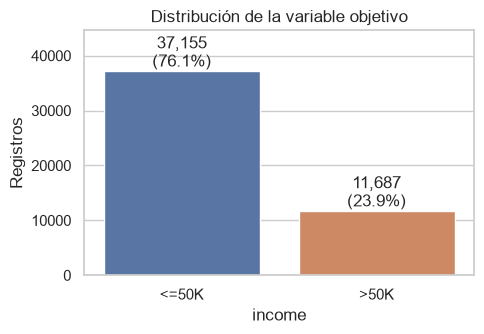

In [8]:
# Balance de clases: determina qué métricas son apropiadas
fig, ax = plt.subplots(figsize=(5, 3.5))
counts = eda["income"].value_counts()
sns.barplot(x=counts.index, y=counts.values, ax=ax, hue=counts.index, legend=False)
for i, v in enumerate(counts.values):
    ax.text(i, v, f"{v:,}\n({v / counts.sum():.1%})", ha="center", va="bottom")
ax.set(title="Distribución de la variable objetivo", xlabel="income", ylabel="Registros",
       ylim=(0, counts.max() * 1.2))
plt.tight_layout(); plt.savefig("outputs/eda_target.png"); plt.show()

La clase positiva (`>50K`) representa solo **≈ 24 %** de los registros: hay **desbalance moderado (3:1)**.
Consecuencia directa: la *accuracy* por sí sola es engañosa (un modelo que siempre diga `<=50K` tendría ≈ 76 %),
por lo que la evaluación usará **F1, precisión, recall y ROC-AUC**, y la partición será **estratificada**.

### 2.4 Distribución de variables numéricas

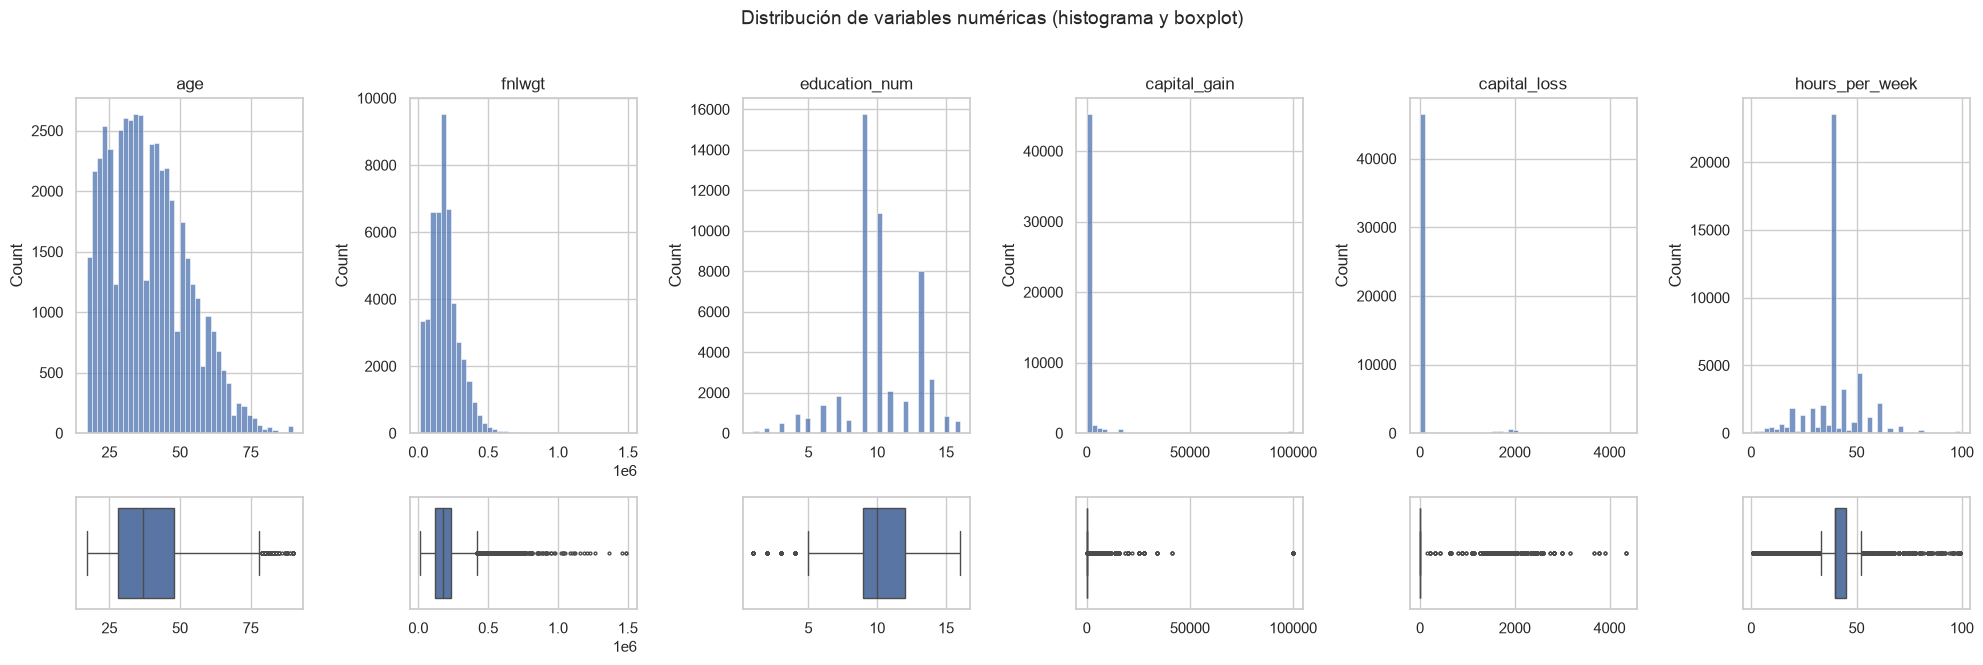

In [9]:
# Histograma + boxplot por variable numérica para ver forma de la distribución y outliers
fig, axes = plt.subplots(2, len(NUM_COLS), figsize=(20, 6.5),
                         gridspec_kw={"height_ratios": [3, 1]})
for i, col in enumerate(NUM_COLS):
    sns.histplot(eda[col], bins=40, ax=axes[0, i], kde=False)
    axes[0, i].set_title(col)
    axes[0, i].set_xlabel("")
    sns.boxplot(x=eda[col], ax=axes[1, i], fliersize=2)
    axes[1, i].set_xlabel("")
fig.suptitle("Distribución de variables numéricas (histograma y boxplot)", y=1.02, fontsize=14)
plt.tight_layout(); plt.savefig("outputs/eda_numericas.png", bbox_inches="tight"); plt.show()

- `age` tiene sesgo a la derecha (más población joven/adulta que mayor).
- `capital_gain` / `capital_loss` son casi constantes en 0 con una cola muy larga; el boxplot marca como
  *outlier* a **cualquier valor distinto de cero**, lo cual indica que la regla IQR no es adecuada para ellas.
- `hours_per_week` está fuertemente concentrada en 40 h; los valores alejados (p. ej. 99) son plausibles
  (jornadas extendidas), no errores.
- `fnlwgt` tiene cola derecha, pero es un **peso de muestreo**, no una característica de la persona.

### 2.5 Distribución de variables categóricas

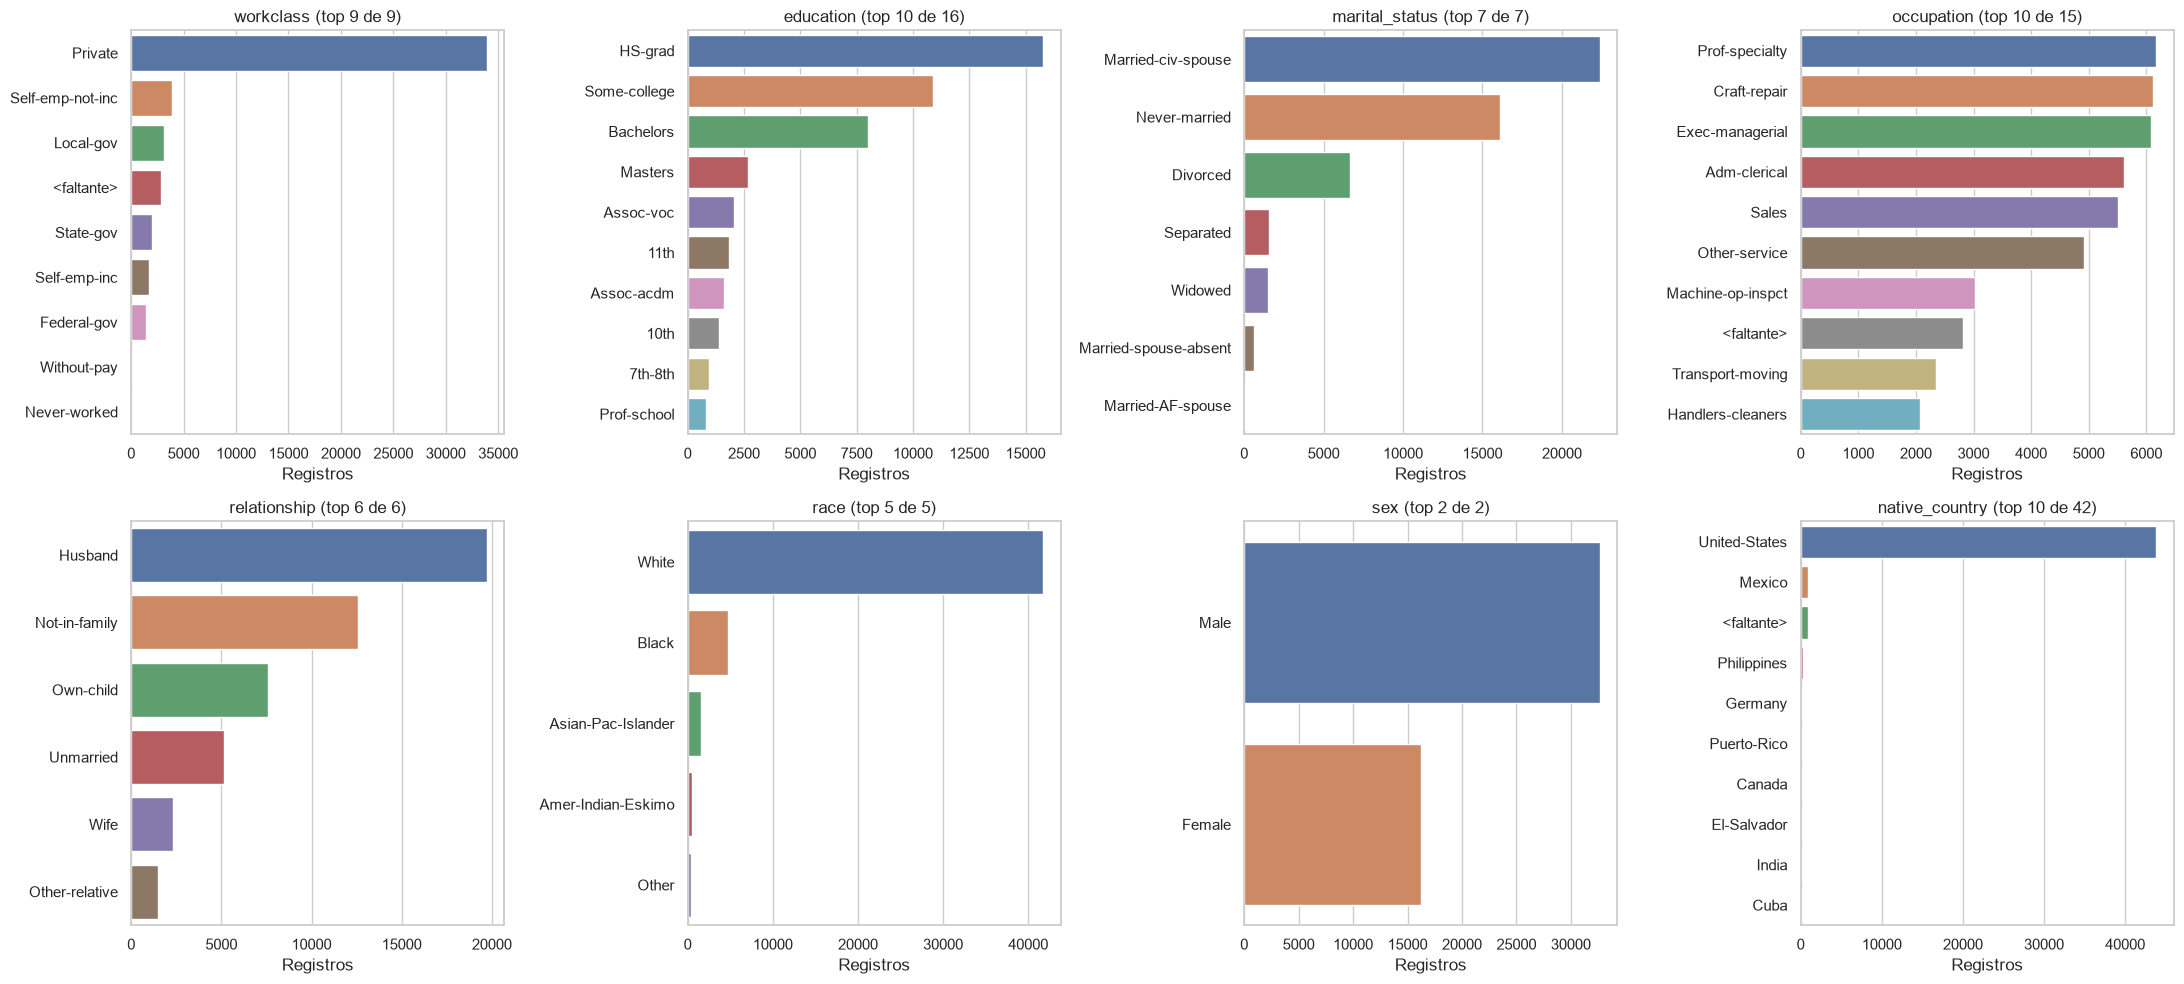

In [10]:
# Frecuencias por categoría (top 10 para variables de alta cardinalidad)
fig, axes = plt.subplots(2, 4, figsize=(22, 10))
for ax, col in zip(axes.ravel(), CAT_COLS):
    vc = eda[col].fillna("<faltante>").value_counts().head(10)
    sns.barplot(x=vc.values, y=vc.index, ax=ax, hue=vc.index, legend=False)
    ax.set(title=f"{col} (top {len(vc)} de {eda[col].nunique(dropna=False)})", xlabel="Registros", ylabel="")
plt.tight_layout(); plt.savefig("outputs/eda_categoricas.png"); plt.show()

- `workclass` es mayoritariamente *Private* (≈ 70 %); `Without-pay` y `Never-worked` tienen muy pocos casos.
- Los faltantes (`<faltante>`) aparecen como una categoría visible en `workclass` y `occupation`.
- `race` y `native_country` están muy desbalanceadas, y `sex` está ≈ 67 % *Male*. Esto es relevante para
  **equidad (*fairness*)**: el modelo podría aprender sesgos históricos del censo.

### 2.6 Relación de las variables con el objetivo

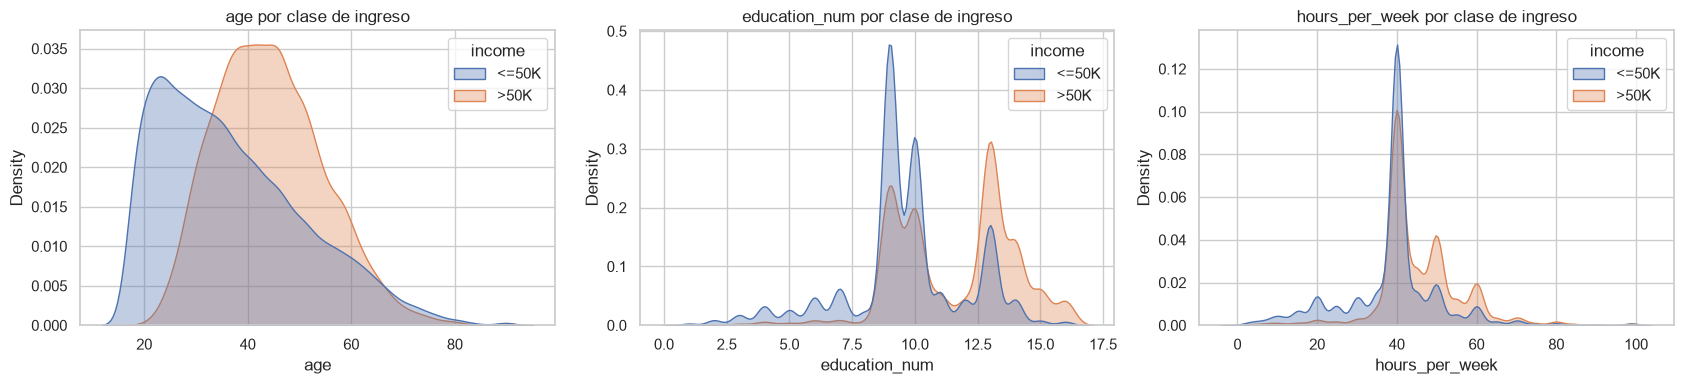

,age,fnlwgt,education_num,capital_gain,capital_loss,hours_per_week
income,,,,,,
<=50K,36.9,190039.6,9.6,147.0,54.2,38.8
>50K,44.3,188470.6,11.6,4042.2,193.5,45.5


In [11]:
# Distribución de variables numéricas clave separadas por clase
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for ax, col in zip(axes, ["age", "education_num", "hours_per_week"]):
    sns.kdeplot(data=eda, x=col, hue="income", common_norm=False, fill=True, alpha=.35, ax=ax)
    ax.set_title(f"{col} por clase de ingreso")
plt.tight_layout(); plt.savefig("outputs/eda_num_vs_target.png"); plt.show()

# Media de cada variable numérica por clase
eda.groupby("income")[NUM_COLS].mean().round(1)

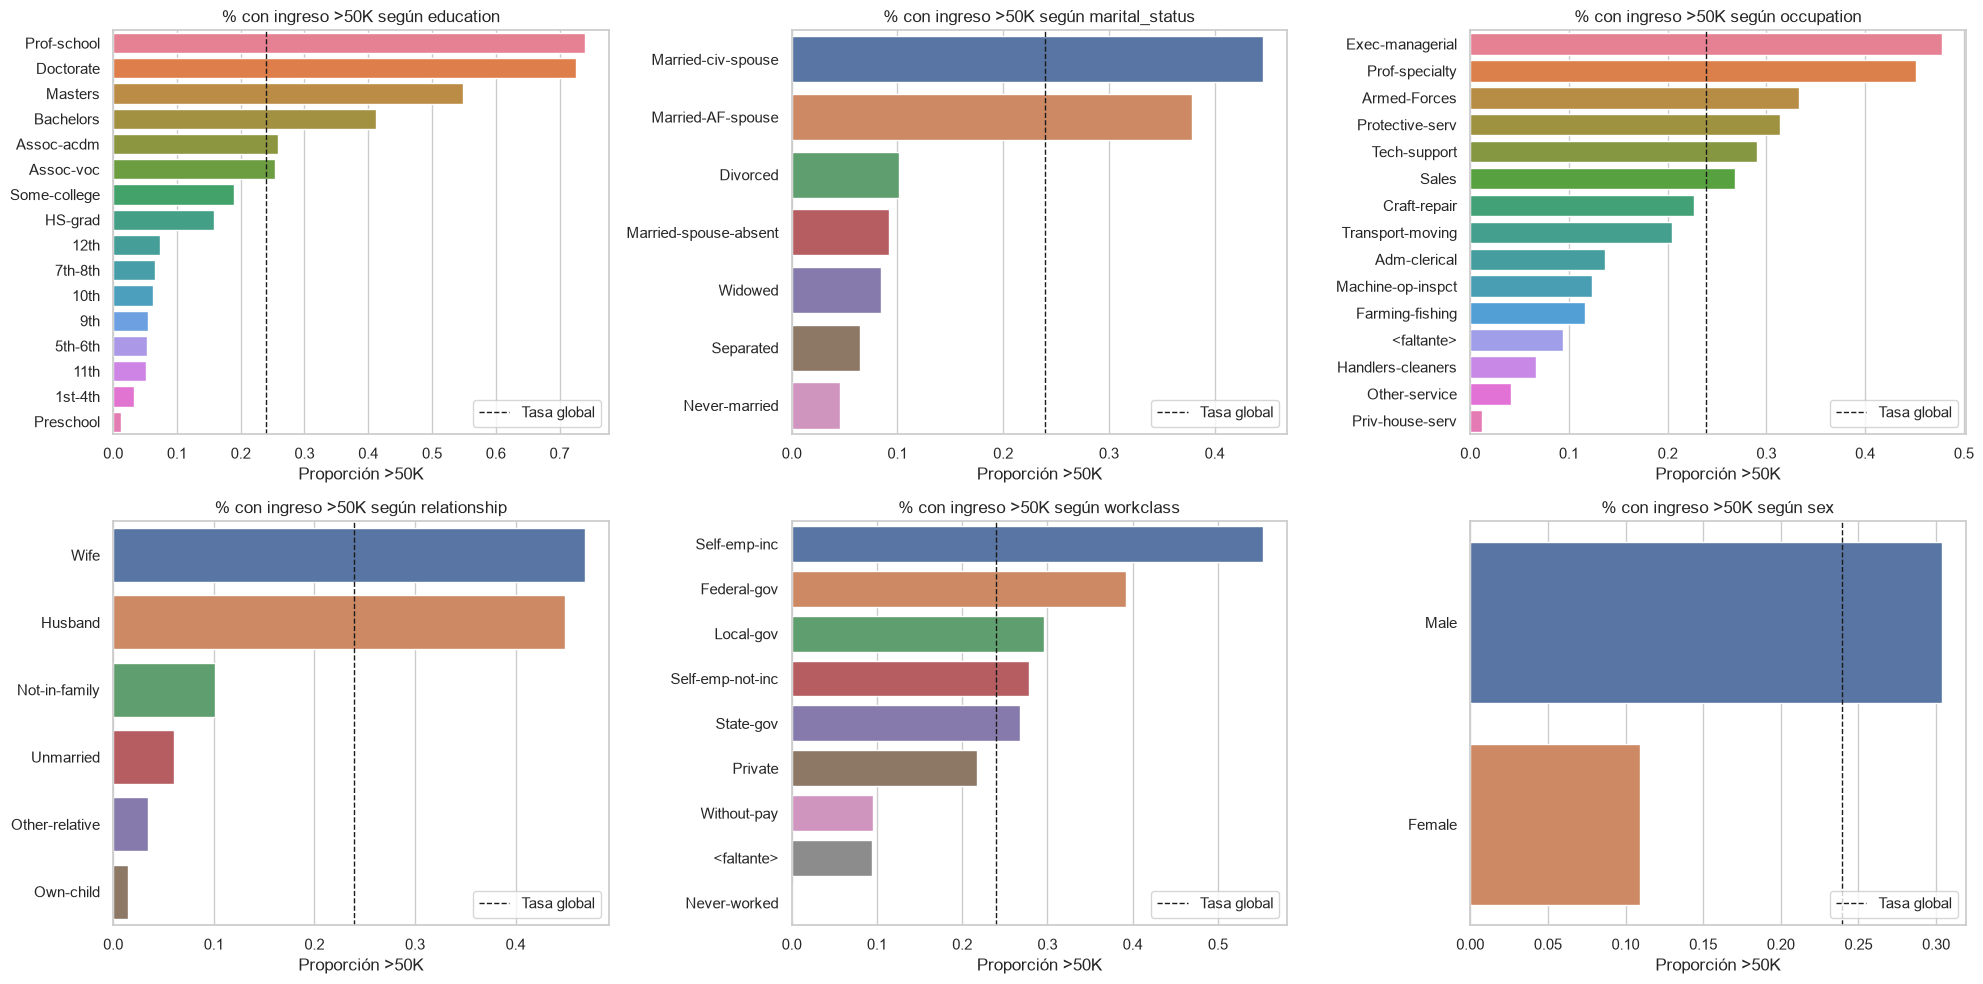

In [12]:
# Tasa de ingreso >50K por categoría: qué categorías concentran los ingresos altos
eda["target"] = (eda["income"] == ">50K").astype(int)
fig, axes = plt.subplots(2, 3, figsize=(20, 10))
for ax, col in zip(axes.ravel(), ["education", "marital_status", "occupation",
                                  "relationship", "workclass", "sex"]):
    rate = eda.groupby(col, dropna=False)["target"].mean().sort_values(ascending=False)
    rate.index = rate.index.fillna("<faltante>")
    sns.barplot(x=rate.values, y=rate.index.astype(str), ax=ax, hue=rate.index.astype(str), legend=False)
    ax.axvline(eda["target"].mean(), color="k", ls="--", lw=1, label="Tasa global")
    ax.set(title=f"% con ingreso >50K según {col}", xlabel="Proporción >50K", ylabel="")
    ax.legend(loc="lower right")
plt.tight_layout(); plt.savefig("outputs/eda_cat_vs_target.png"); plt.show()

**Relaciones más informativas:**
- **Educación**: la proporción de `>50K` crece casi monotónicamente con el nivel educativo
  (Doctorate y Prof-school > 70 % vs. < 10 % en niveles básicos).
- **Estado civil / relación**: `Married-civ-spouse`, `Husband` y `Wife` concentran los ingresos altos (≈ 45 %),
  mientras que `Never-married` y `Own-child` casi nunca superan 50K.
- **Ocupación**: `Exec-managerial` y `Prof-specialty` duplican la tasa global; `Priv-house-serv` y
  `Handlers-cleaners` están muy por debajo.
- **Edad y horas**: las personas con `>50K` son en promedio ≈ 7 años mayores (44.3 vs 36.9) y trabajan ≈ 7 h más por semana (45.5 vs 38.8).
- Los registros con `workclass`/`occupation` **faltante** tienen una tasa de `>50K` muy baja (≈ 10 %):
  **el faltante es informativo**, dato clave para decidir cómo imputarlo.

### 2.7 Correlaciones entre variables numéricas

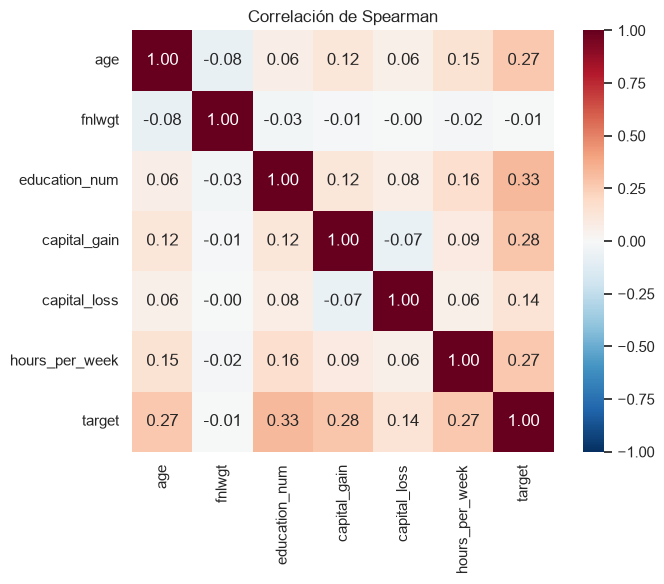

In [13]:
# Correlación de Spearman (robusta a asimetría y outliers), incluyendo el objetivo binario
corr = eda[NUM_COLS + ["target"]].corr(method="spearman")
fig, ax = plt.subplots(figsize=(7.5, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, square=True, ax=ax)
ax.set_title("Correlación de Spearman")
plt.tight_layout(); plt.savefig("outputs/eda_correlacion.png"); plt.show()

In [14]:
# ¿education y education_num codifican exactamente la misma información?
mapping = eda.groupby("education")["education_num"].nunique()
print("Valores distintos de education_num por cada categoría de education:", mapping.unique())
eda.groupby("education")["education_num"].first().sort_values().to_frame().T

Valores distintos de education_num por cada categoría de education: [1]


education,Preschool,1st-4th,5th-6th,7th-8th,9th,10th,11th,12th,HS-grad,Some-college,Assoc-voc,Assoc-acdm,Bachelors,Masters,Prof-school,Doctorate
education_num,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16


- Ninguna variable numérica tiene correlación fuerte con otra (|ρ| < 0.2), así que **no hay multicolinealidad**
  problemática entre ellas.
- `education_num`, `age`, `hours_per_week` y `capital_gain` son las más asociadas con el objetivo.
- `fnlwgt` tiene correlación **≈ 0** con el objetivo, consistente con que es un peso muestral.
- `education` ↔ `education_num` es una correspondencia **1 a 1**: son la misma variable en dos formatos.

## Paso 3. Limpieza de datos

Cada problema detectado en el EDA se trata en una celda propia con su **decisión y justificación**.
Se registra un *log* de cuántas filas/columnas afecta cada paso para tener trazabilidad.

> **Principio anti-*leakage*:** en este paso solo se aplican transformaciones **deterministas por fila**
> (corregir etiquetas, eliminar duplicados, normalizar texto). Todo lo que *aprende* de los datos
> (escalado, codificación) se hace **dentro del Pipeline** y se ajusta solo con el conjunto de entrenamiento.

In [15]:
df = df_raw.copy()
cleaning_log = []   # bitácora de decisiones de limpieza

def log_step(step, detail, before, after):
    # Guarda el efecto de cada paso de limpieza para la tabla resumen final
    cleaning_log.append({"paso": step, "detalle": detail, "filas_antes": before, "filas_despues": after})

### 3.1 Tipos incorrectos y formato de texto
**Problema:** columnas de texto con posibles espacios extra y la variable objetivo como texto con 4 variantes.
`source` es una columna auxiliar sin valor predictivo.

**Decisión:**
- Quitar espacios en blanco al inicio/fin de todas las columnas de texto.
- Unificar la etiqueta (`<=50K.` → `<=50K`) y convertir el objetivo a **entero binario** (`1 = >50K`).
- Verificar que las columnas numéricas sean realmente `int64` (no texto).
- Eliminar `source` (solo servía para auditoría).

In [16]:
n0 = len(df)
str_cols = df.select_dtypes(exclude="number").columns
df[str_cols] = df[str_cols].apply(lambda s: s.str.strip())

# Unificación de la etiqueta y conversión a binario
df["income"] = df["income"].str.rstrip(".")
assert set(df["income"].unique()) == {"<=50K", ">50K"}, "Etiquetas inesperadas en income"
df["target"] = (df["income"] == ">50K").astype(int)
df = df.drop(columns=["income", "source"])

# Validación de tipos numéricos
print(df[NUM_COLS].dtypes)
assert all(pd.api.types.is_integer_dtype(df[c]) for c in NUM_COLS)
log_step("Tipos/formato", "strip de texto, etiqueta unificada y binarizada", n0, len(df))
print("\nDistribución del objetivo:", df["target"].value_counts().to_dict())

age               int64
fnlwgt            int64
education_num     int64
capital_gain      int64
capital_loss      int64
hours_per_week    int64
dtype: object

Distribución del objetivo: {0: 37155, 1: 11687}


### 3.2 Duplicados
**Problema:** existen filas idénticas en *todas* las columnas, incluida `fnlwgt` (peso muestral con
~28 mil valores distintos). Que dos personas coincidan en las 15 columnas, incluido ese peso, es
muy improbable; lo más probable es que sean registros repetidos.

**Decisión:** eliminar duplicados exactos conservando la primera ocurrencia. Además de inflar el peso de esos
casos, si un duplicado cae en entrenamiento y su copia en prueba, se **sobreestima** el desempeño (fuga de datos).

In [17]:
n0 = len(df)
dups = df.duplicated()
print(f"Duplicados exactos encontrados: {dups.sum()} ({dups.mean():.3%} del total)")
display(df[df.duplicated(keep=False)].sort_values(list(df.columns)).head(6))
df = df.drop_duplicates(keep="first").reset_index(drop=True)
log_step("Duplicados", "drop_duplicates exactos", n0, len(df))
print(f"Filas: {n0:,} -> {len(df):,}")

Duplicados exactos encontrados: 52 (0.106% del total)


,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,target
24667,17,Private,153021,12th,8,Never-married,Sales,Own-child,White,Female,0,0,20,United-States,0
36713,17,Private,153021,12th,8,Never-married,Sales,Own-child,White,Female,0,0,20,United-States,0
36461,18,Self-emp-inc,378036,12th,8,Never-married,Farming-fishing,Own-child,White,Male,0,0,10,United-States,0
48521,18,Self-emp-inc,378036,12th,8,Never-married,Farming-fishing,Own-child,White,Male,0,0,10,United-States,0
10094,19,?,167428,Some-college,10,Never-married,?,Own-child,White,Male,0,0,40,United-States,0
40677,19,?,167428,Some-college,10,Never-married,?,Own-child,White,Male,0,0,40,United-States,0


Filas: 48,842 -> 48,790


### 3.3 Valores faltantes
**Problema:** faltantes codificados como `'?'` en `workclass` (≈ 5.7 %), `occupation` (≈ 5.8 %) y
`native_country` (≈ 1.8 %).

**Análisis:** se revisa si los faltantes son aleatorios o tienen patrón.

In [18]:
df = df.replace("?", np.nan)
miss = df.isna().sum()
print("Faltantes por columna:\n", miss[miss > 0], "\n")

# ¿Los faltantes de workclass y occupation ocurren en las mismas filas?
both = (df["workclass"].isna() & df["occupation"].isna()).sum()
print(f"Filas con workclass y occupation faltantes a la vez: {both:,}")
print(f"Filas con occupation faltante pero workclass presente: "
      f"{(df['occupation'].isna() & df['workclass'].notna()).sum()} "
      f"-> workclass = {df.loc[df['occupation'].isna() & df['workclass'].notna(), 'workclass'].unique()}")

# Tasa de >50K con y sin faltante: ¿el faltante es informativo?
for col in ["workclass", "occupation", "native_country"]:
    r = df.groupby(df[col].isna())["target"].mean()
    print(f"{col:<15} tasa >50K | presente: {r[False]:.1%}  faltante: {r[True]:.1%}")

Faltantes por columna:
 workclass         2795
occupation        2805
native_country     856
dtype: int64 

Filas con workclass y occupation faltantes a la vez: 2,795
Filas con occupation faltante pero workclass presente: 10 -> workclass = <ArrowStringArray>
['Never-worked']
Length: 1, dtype: str
workclass       tasa >50K | presente: 24.8%  faltante: 9.5%
occupation      tasa >50K | presente: 24.8%  faltante: 9.4%
native_country  tasa >50K | presente: 23.9%  faltante: 25.7%


**Hallazgos:**
- **Todas** las filas con `workclass` faltante también tienen `occupation` faltante; las 10 filas restantes
  con `occupation` faltante son `Never-worked` (personas que nunca han trabajado). El patrón **no es aleatorio**:
  corresponde a personas sin empleo formal/registrado.
- En `workclass`/`occupation`, la tasa de `>50K` cuando falta el dato (≈ 9.5 %) es **menos de la mitad** de la
  tasa cuando está presente (≈ 24.8 %): el faltante **es informativo**.
- En `native_country` la tasa es similar con y sin dato (25.7 % vs 23.9 %): el faltante parece **aleatorio** y
  afecta solo al 1.75 % de las filas.

**Decisión:** **imputar con la categoría explícita `"Unknown"`** en las tres columnas. En `workclass` y
`occupation` se preserva la señal del faltante; en `native_country` se usa la misma regla por consistencia,
ya que con tan pocos casos el efecto es mínimo y evita descartar filas. Se descartaron las alternativas:
- *Eliminar filas*: perdería ≈ 7 % de los datos y sesgaría la muestra (quitaría justo a personas con ingresos bajos).
- *Imputar con la moda* (`Private`, `Prof-specialty`, `United-States`): mezclaría a este grupo con otro de
  comportamiento distinto y destruiría la señal informativa del faltante.

Como `"Unknown"` es una constante (no se aprende de los datos), aplicarla antes de dividir **no genera *leakage***.

In [19]:
n0 = len(df)
MISSING_COLS = ["workclass", "occupation", "native_country"]
df[MISSING_COLS] = df[MISSING_COLS].fillna("Unknown")
assert df.isna().sum().sum() == 0
log_step("Faltantes", "'?' -> 'Unknown' en workclass, occupation, native_country", n0, len(df))
print("NaN restantes:", df.isna().sum().sum())

NaN restantes: 0


### 3.4 Outliers
Se cuantifican con la regla de **Tukey (1.5 × IQR)** y se analiza si son errores o valores legítimos.

In [20]:
def iqr_outliers(s):
    # Devuelve una máscara booleana de valores fuera de [Q1 - 1.5·IQR, Q3 + 1.5·IQR]
    q1, q3 = s.quantile([.25, .75])
    iqr = q3 - q1
    return (s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)

out = pd.DataFrame({c: {"n_outliers": iqr_outliers(df[c]).sum(),
                        "%": round(100 * iqr_outliers(df[c]).mean(), 2),
                        "min": df[c].min(), "max": df[c].max()} for c in NUM_COLS}).T
out

,n_outliers,%,min,max
age,215.0,0.44,17.0,90.0
fnlwgt,1453.0,2.98,12285.0,1490400.0
education_num,1787.0,3.66,1.0,16.0
capital_gain,4035.0,8.27,0.0,99999.0
capital_loss,2282.0,4.68,0.0,4356.0
hours_per_week,13486.0,27.64,1.0,99.0


In [21]:
# Casos extremos específicos que conviene inspeccionar
print("capital_gain = 99,999 (posible top-coding):", (df["capital_gain"] == 99999).sum(),
      f"| tasa >50K en ese grupo: {df.loc[df.capital_gain == 99999, 'target'].mean():.0%}")
print("Siguiente valor más alto de capital_gain:", df.loc[df.capital_gain < 99999, "capital_gain"].max())
print("hours_per_week >= 80:", (df["hours_per_week"] >= 80).sum(),
      "| hours_per_week <= 5:", (df["hours_per_week"] <= 5).sum())
print("age == 90:", (df["age"] == 90).sum())

capital_gain = 99,999 (posible top-coding): 244 | tasa >50K en ese grupo: 100%
Siguiente valor más alto de capital_gain: 41310
hours_per_week >= 80: 528 | hours_per_week <= 5: 318
age == 90: 54


**Decisiones por variable:**

| Variable | Diagnóstico | Decisión |
|---|---|---|
| `capital_gain`, `capital_loss` | La regla IQR marca como outlier a todo valor ≠ 0 (≈ 8 % y 5 %). El valor 99,999 es un **tope de registro** del censo y el 100 % de esos casos son `>50K`: es señal real, no ruido. | **No eliminar.** Aplicar **`log1p`** dentro del pipeline para comprimir la cola larga y reducir la influencia de valores extremos en un modelo lineal. |
| `hours_per_week` | IQR marca ≈ 27.6 % como outlier solo porque Q1 = Q3 = 40 h (IQR muy estrecho); valores de 1 a 99 son posibles (medio tiempo, jornadas extendidas). | **Conservar.** Son comportamientos reales; el escalado estándar es suficiente. |
| `age` | 215 outliers (0.44 %), rango 17–90 plausible; 90 parece tope del censo (54 casos). | **Conservar.** |
| `fnlwgt` | Outliers en la cola derecha, pero es un peso muestral sin relación con el objetivo (ρ ≈ 0). | **Eliminar la columna** (ver 3.5). |
| `education_num` | Outliers en niveles muy bajos (Preschool, 1st–4th): son categorías válidas. | **Conservar.** |

Se evitó eliminar filas por outliers porque en este dataset los valores extremos son **legítimos y
predictivos**; borrarlos quitaría precisamente a los casos de ingresos altos que queremos detectar.

### 3.5 Selección de columnas (redundancia e irrelevancia)
**Decisión:**
- **Eliminar `education`**: es una codificación 1 a 1 de `education_num` (verificado en el EDA). Mantener ambas
  duplica información; se conserva `education_num` porque preserva el **orden** natural del nivel educativo.
- **Eliminar `fnlwgt`**: es un *peso de muestreo* del censo (cuántas personas representa la fila), no un atributo
  del individuo, y su correlación con el objetivo es ≈ 0.
- **Se conservan `race` y `sex`** para el baseline, pero se reconocen como **atributos sensibles**: en una
  siguiente iteración se debería auditar la equidad del modelo.

In [22]:
n0 = len(df)
df = df.drop(columns=["education", "fnlwgt"])
log_step("Columnas", "drop education (redundante) y fnlwgt (peso muestral)", n0, len(df))

# Las categóricas se convierten a dtype 'category' (tipo correcto, menor memoria)
CAT_FEATURES = ["workclass", "marital_status", "occupation", "relationship", "race", "sex", "native_country"]
NUM_FEATURES = ["age", "education_num", "hours_per_week"]
LOG_FEATURES = ["capital_gain", "capital_loss"]      # se les aplicará log1p en el pipeline
df[CAT_FEATURES] = df[CAT_FEATURES].astype("category")
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 48790 entries, 0 to 48789
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype   
---  ------          --------------  -----   
 0   age             48790 non-null  int64   
 1   workclass       48790 non-null  category
 2   education_num   48790 non-null  int64   
 3   marital_status  48790 non-null  category
 4   occupation      48790 non-null  category
 5   relationship    48790 non-null  category
 6   race            48790 non-null  category
 7   sex             48790 non-null  category
 8   capital_gain    48790 non-null  int64   
 9   capital_loss    48790 non-null  int64   
 10  hours_per_week  48790 non-null  int64   
 11  native_country  48790 non-null  category
 12  target          48790 non-null  int64   
dtypes: category(7), int64(6)
memory usage: 2.6 MB


### 3.6 Resumen de la limpieza

In [23]:
log_df = pd.DataFrame(cleaning_log)
log_df["filas_eliminadas"] = log_df["filas_antes"] - log_df["filas_despues"]
log_df.to_csv("outputs/cleaning_log.csv", index=False)   # se registrará en MLflow
print(f"Dataset final: {df.shape[0]:,} filas x {df.shape[1] - 1} predictoras + target")
log_df

Dataset final: 48,790 filas x 12 predictoras + target


,paso,detalle,filas_antes,filas_despues,filas_eliminadas
0,Tipos/formato,"strip de texto, etiqueta unificada y binarizada",48842,48842,0
1,Duplicados,drop_duplicates exactos,48842,48790,52
2,Faltantes,"'?' -> 'Unknown' en workclass, occupation, nat...",48790,48790,0
3,Columnas,drop education (redundante) y fnlwgt (peso mue...,48790,48790,0


## Paso 4. Entrenamiento del modelo base

### 4.1 Elección del baseline
Se elige **Regresión Logística** porque:
- Es el modelo lineal estándar para **clasificación binaria**: rápido, estable y con pocos hiperparámetros.
- Produce **probabilidades**, lo que permite calcular ROC-AUC y ajustar el umbral más adelante.
- Es **interpretable** (coeficientes = efecto de cada variable sobre los *log-odds*), útil como punto de partida.

Adicionalmente se entrena un **`DummyClassifier`** (predice siempre la clase mayoritaria) como *piso* de referencia:
cualquier modelo útil debe superarlo claramente.

Se usa `class_weight="balanced"` para compensar el desbalance 76/24, de modo que el modelo no ignore la
clase minoritaria (`>50K`).

### 4.2 División de datos
- **80 % entrenamiento / 20 % prueba**, **estratificado** por el objetivo para conservar la proporción de clases.
- Semilla fija (`random_state=42`) para reproducibilidad.
- El conjunto de prueba **no se usa** para ninguna decisión de modelado; solo para la evaluación final.

In [24]:
TARGET = "target"
FEATURES = NUM_FEATURES + LOG_FEATURES + CAT_FEATURES
TEST_SIZE = 0.20

X = df[FEATURES]
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=RANDOM_STATE)

# Verificación de la estratificación
print(f"Train: {X_train.shape} | Test: {X_test.shape}")
print(f"% >50K  train: {y_train.mean():.3%} | test: {y_test.mean():.3%}")

Train: (39032, 12) | Test: (9758, 12)
% >50K  train: 23.942% | test: 23.939%


### 4.3 Pipeline de preprocesamiento + modelo
Encapsular todo en un `Pipeline` garantiza que el escalado y la codificación se **ajusten solo con
entrenamiento** (sin fuga de información del conjunto de prueba) y que el mismo objeto pueda serializarse y
servirse en producción con exactamente las mismas transformaciones.

| Grupo | Columnas | Transformación |
|---|---|---|
| Numéricas | `age`, `education_num`, `hours_per_week` | `StandardScaler` |
| Asimétricas | `capital_gain`, `capital_loss` | `log1p` → `StandardScaler` |
| Categóricas | 7 columnas nominales | `OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=20)` |

`min_frequency=20` agrupa categorías muy raras (p. ej. países con pocos registros) en una sola columna
“infrequent”, evitando coeficientes inestables; `handle_unknown="infrequent_if_exist"` envía a ese mismo grupo cualquier categoría nueva que aparezca en producción, en lugar de fallar

In [25]:
# Hiperparámetros del baseline (se registrarán en MLflow)
MODEL_PARAMS = {"C": 1.0, "penalty": "l2", "solver": "lbfgs", "max_iter": 1000,
                "class_weight": "balanced", "random_state": RANDOM_STATE}
OHE_MIN_FREQ = 20

preprocessor = ColumnTransformer(transformers=[
    ("num", StandardScaler(), NUM_FEATURES),
    ("log", Pipeline([("log1p", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
                      ("scaler", StandardScaler())]), LOG_FEATURES),
    ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=OHE_MIN_FREQ,
                          sparse_output=False), CAT_FEATURES),
])

model = Pipeline([("preprocessor", preprocessor),
                  ("classifier", LogisticRegression(**MODEL_PARAMS))])

# Validación cruzada estratificada (5 folds) SOLO sobre entrenamiento: estima la estabilidad del modelo
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_f1 = cross_val_score(model, X_train, y_train, cv=cv, scoring="f1")
cv_auc = cross_val_score(model, X_train, y_train, cv=cv, scoring="roc_auc")
print(f"CV F1      : {cv_f1.mean():.4f} ± {cv_f1.std():.4f}")
print(f"CV ROC-AUC : {cv_auc.mean():.4f} ± {cv_auc.std():.4f}")

# Entrenamiento final con todo el conjunto de entrenamiento
model.fit(X_train, y_train)
n_feat = model.named_steps["preprocessor"].get_feature_names_out().shape[0]
print(f"\nModelo entrenado. Número de variables tras el preprocesamiento: {n_feat}")

CV F1      : 0.6712 ± 0.0063
CV ROC-AUC : 0.8987 ± 0.0040



Modelo entrenado. Número de variables tras el preprocesamiento: 84


In [26]:
# Baseline trivial de referencia: siempre predice la clase mayoritaria
dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)

## Paso 5. Evaluación del modelo

**Métricas elegidas** (coherentes con clasificación binaria desbalanceada):
- **F1-score (métrica principal)**: media armónica de precisión y recall de la clase `>50K`; penaliza
  tanto falsos positivos como falsos negativos y no se “infla” con la clase mayoritaria.
- **ROC-AUC**: capacidad de *ordenar* correctamente a positivos sobre negativos, independiente del umbral.
- **Precisión** y **Recall**: para entender el tipo de error que comete el modelo.
- **Accuracy**: se reporta solo como referencia, comparándola con el Dummy.

In [27]:
def evaluate(clf, X_, y_):
    # Calcula las métricas de clasificación sobre un conjunto dado
    pred = clf.predict(X_)
    proba = clf.predict_proba(X_)[:, 1]
    return {"accuracy": accuracy_score(y_, pred),
            "precision": precision_score(y_, pred, zero_division=0),
            "recall": recall_score(y_, pred),
            "f1": f1_score(y_, pred),
            "roc_auc": roc_auc_score(y_, proba)}

train_metrics = evaluate(model, X_train, y_train)
test_metrics = evaluate(model, X_test, y_test)
dummy_metrics = evaluate(dummy, X_test, y_test)

results = pd.DataFrame({"LogReg - train": train_metrics,
                        "LogReg - test": test_metrics,
                        "Dummy - test": dummy_metrics}).round(4)
results

,LogReg - train,LogReg - test,Dummy - test
accuracy,0.8037,0.8025,0.7606
precision,0.5597,0.5578,0.0000
recall,0.8441,0.8450,0.0000
f1,0.6731,0.6720,0.0000
roc_auc,0.9003,0.9022,0.5000


              precision    recall  f1-score   support

       <=50K      0.942     0.789     0.859      7422
        >50K      0.558     0.845     0.672      2336

    accuracy                          0.803      9758
   macro avg      0.750     0.817     0.765      9758
weighted avg      0.850     0.803     0.814      9758



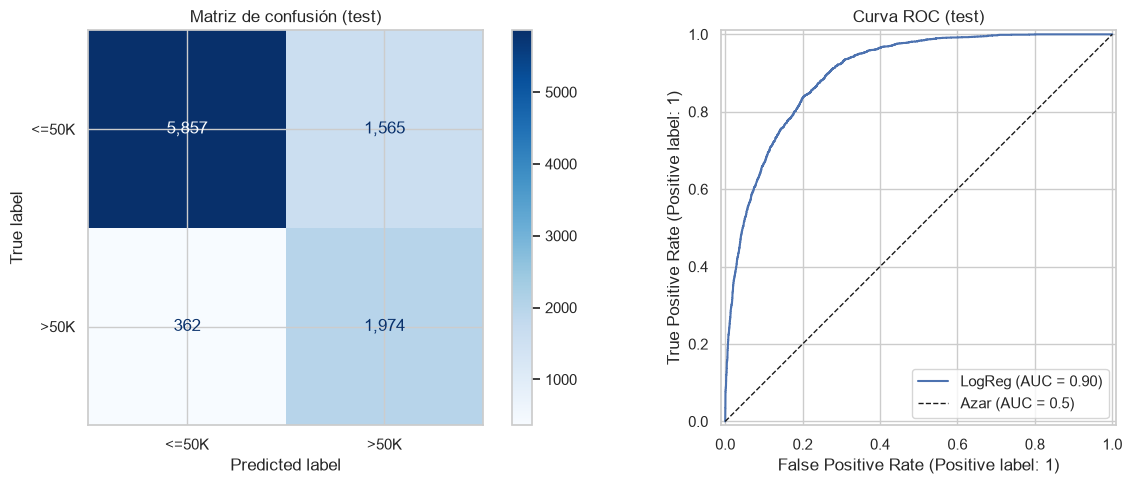

TN=5,857  FP=1,565  FN=362  TP=1,974


In [28]:
y_pred = model.predict(X_test)
print(classification_report(y_test, y_pred, target_names=["<=50K", ">50K"], digits=3))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=["<=50K", ">50K"],
                                        cmap="Blues", values_format=",", ax=axes[0])
axes[0].set_title("Matriz de confusión (test)")
RocCurveDisplay.from_estimator(model, X_test, y_test, ax=axes[1], name="LogReg")
axes[1].plot([0, 1], [0, 1], "k--", lw=1, label="Azar (AUC = 0.5)")
axes[1].legend(loc="lower right"); axes[1].set_title("Curva ROC (test)")
plt.tight_layout(); plt.savefig("outputs/evaluation.png"); plt.show()

tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
print(f"TN={tn:,}  FP={fp:,}  FN={fn:,}  TP={tp:,}")

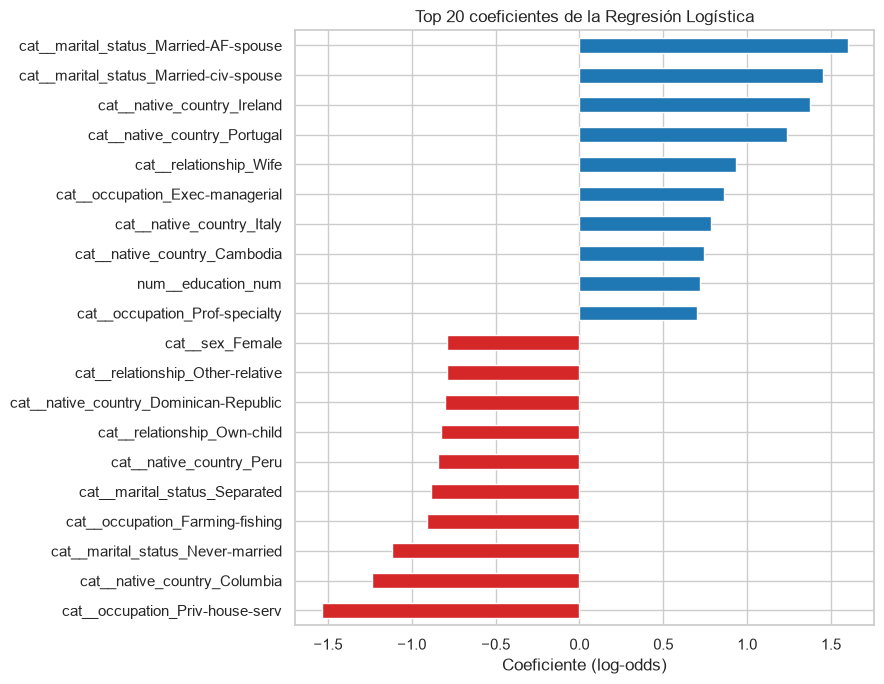

In [29]:
# Interpretabilidad: coeficientes más influyentes (positivos -> aumentan prob. de >50K)
coefs = pd.Series(model.named_steps["classifier"].coef_[0],
                  index=model.named_steps["preprocessor"].get_feature_names_out())
top = pd.concat([coefs.nlargest(10), coefs.nsmallest(10)]).sort_values()
fig, ax = plt.subplots(figsize=(9, 7))
top.plot.barh(ax=ax, color=np.where(top > 0, "tab:blue", "tab:red"))
ax.set(title="Top 20 coeficientes de la Regresión Logística", xlabel="Coeficiente (log-odds)")
plt.tight_layout(); plt.savefig("outputs/coeficientes.png"); plt.show()

### 5.1 Interpretación de resultados

**1. El modelo aprende señal real.** Frente al `DummyClassifier` (accuracy 0.761, F1 0, ROC-AUC 0.5), la regresión
logística alcanza **F1 = 0.672** y **ROC-AUC = 0.902** en prueba. La accuracy solo sube de 0.761 a 0.803 (+4 pp),
lo que confirma que la accuracy **no** sirve para comparar modelos en este problema desbalanceado: el Dummy “acierta”
76 % sin aprender nada.

**2. ROC-AUC = 0.902:** si se toma al azar una persona con `>50K` y otra con `<=50K`, el modelo asigna mayor
probabilidad a la primera el **90 % de las veces**. La capacidad de *ordenar* el riesgo es buena para un modelo lineal
sin ajuste de hiperparámetros.

**3. Tipo de error (umbral 0.5 + `class_weight="balanced"`):**
- **Recall = 0.845:** el modelo detecta 1,974 de las 2,336 personas con `>50K`; solo se le escapan 362 (FN).
- **Precisión = 0.558:** de cada 100 personas que el modelo marca como `>50K`, ≈ 56 lo son realmente; hay
  1,565 falsos positivos.
- Este balance es consecuencia directa de `class_weight="balanced"`, que penaliza más los errores en la clase
  minoritaria y **mueve el modelo hacia el recall**. Si el caso de uso fuera, por ejemplo, ofrecer un producto
  financiero premium donde un falso positivo es costoso, convendría subir el umbral para ganar precisión; si fuera
  identificar a la mayor cantidad posible de candidatos, este punto de operación es adecuado. **La métrica y el umbral
  deben definirse con el costo de negocio de cada error.**

**4. Sin sobreajuste, pero con sesgo (*underfitting* leve).** Las métricas de entrenamiento y prueba son prácticamente
iguales (F1 0.673 vs 0.672; AUC 0.900 vs 0.902) y la validación cruzada es muy estable (F1 0.671 ± 0.006). El modelo
generaliza bien, pero su techo lo pone su **linealidad**: no captura interacciones (p. ej. edad × educación) ni
relaciones no lineales. Hay margen para mejorar con modelos más flexibles (árboles de *boosting*).

**5. Coeficientes.** Los efectos más fuertes y estables son coherentes con el EDA: estar casado
(`Married-civ-spouse`, `Wife`), ocupaciones `Exec-managerial`/`Prof-specialty` y mayor `education_num` aumentan la
probabilidad de `>50K`; `Never-married`, `Own-child` y `Priv-house-serv` la reducen. Dos alertas:
- Varios países con pocos registros (Irlanda, Portugal, Colombia, Perú) tienen coeficientes grandes; son
  **estimaciones ruidosas** por tamaño de muestra, no relaciones confiables.
- `sex_Female` tiene coeficiente negativo (−0.79): el modelo reproduce la brecha salarial histórica del censo de 1994.
  Antes de usar un modelo así para decisiones sobre personas sería obligatorio un **análisis de equidad**.

**Conclusión:** el baseline es un punto de partida sólido y reproducible (F1 ≈ 0.67, AUC ≈ 0.90). Cualquier modelo
futuro debe superar estos valores en el mismo conjunto de prueba para justificar su mayor complejidad.

## Paso 6. Registro del experimento en MLflow Tracking

Se registra en un servidor local (`sqlite:///mlflow.db`, misma base usada en la Semana 1):
- **Parámetros**: hiperparámetros del modelo, configuración de la partición y del preprocesamiento,
  y metadatos del dataset (filas, columnas, decisiones de limpieza).
- **Métricas**: métricas de test, de entrenamiento, de validación cruzada y del Dummy de referencia.
- **Tags**: tipo de modelo, etapa (*baseline*), autor y dataset.
- **Artefactos**: gráficas de EDA y evaluación, bitácora de limpieza, reporte de clasificación y el
  **modelo serializado** (pipeline completo con firma de entrada/salida y ejemplo de entrada).

In [30]:
# Configuración del backend de tracking y del experimento
mlflow.set_tracking_uri("sqlite:///mlflow.db")
EXPERIMENT_NAME = "TC5061-adult-income-baseline"
mlflow.set_experiment(EXPERIMENT_NAME)

with mlflow.start_run(run_name="logreg-baseline") as run:
    # --- Tags descriptivos del run ---
    mlflow.set_tags({"stage": "baseline", "model_type": "LogisticRegression",
                     "dataset": "UCI Adult (Census Income)", "author": "Fernando Mejía Laguna",
                     "problem_type": "binary_classification"})

    # --- Parámetros: modelo, partición, preprocesamiento y datos ---
    mlflow.log_params({f"model_{k}": v for k, v in MODEL_PARAMS.items()})
    mlflow.log_params({
        "test_size": TEST_SIZE, "stratify": True, "split_random_state": RANDOM_STATE,
        "cv_folds": cv.get_n_splits(),
        "num_scaler": "StandardScaler", "log_features": ",".join(LOG_FEATURES),
        "cat_encoder": "OneHotEncoder", "ohe_min_frequency": OHE_MIN_FREQ,
        "missing_strategy": "constant_Unknown", "duplicates": "dropped",
        "outliers_strategy": "keep + log1p(capital_*)", "dropped_columns": "education,fnlwgt",
        "n_rows_raw": len(df_raw), "n_rows_clean": len(df),
        "n_train": len(X_train), "n_test": len(X_test),
        "n_features_in": len(FEATURES), "n_features_encoded": n_feat,
    })

    # --- Métricas ---
    mlflow.log_metrics({f"test_{k}": v for k, v in test_metrics.items()})
    mlflow.log_metrics({f"train_{k}": v for k, v in train_metrics.items()})
    mlflow.log_metrics({f"dummy_test_{k}": v for k, v in dummy_metrics.items()})
    mlflow.log_metrics({"cv_f1_mean": cv_f1.mean(), "cv_f1_std": cv_f1.std(),
                        "cv_roc_auc_mean": cv_auc.mean(), "cv_roc_auc_std": cv_auc.std()})
    for i, (f1_i, auc_i) in enumerate(zip(cv_f1, cv_auc)):   # métrica por fold (gráfica en la UI)
        mlflow.log_metric("cv_f1_fold", f1_i, step=i)
        mlflow.log_metric("cv_roc_auc_fold", auc_i, step=i)

    # --- Artefactos: figuras, bitácora de limpieza y reporte ---
    mlflow.log_artifacts("outputs", artifact_path="figures_and_logs")
    mlflow.log_text(classification_report(y_test, y_pred, target_names=["<=50K", ">50K"], digits=4),
                    "classification_report.txt")

    # --- Modelo: pipeline completo con firma y ejemplo de entrada ---
    signature = infer_signature(X_train, model.predict(X_train))
    mlflow.sklearn.log_model(model, name="model", signature=signature,
                             input_example=X_train.head(3))

    RUN_ID = run.info.run_id

print(f"Experimento : {EXPERIMENT_NAME}")
print(f"Run ID      : {RUN_ID}")

2026/10/04 21:33:22 INFO mlflow.tracking.fluent: Experiment with name 'TC5061-adult-income-baseline' does not exist. Creating a new experiment.


2026/10/04 21:33:28 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


Experimento : TC5061-adult-income-baseline
Run ID      : 195d3631e73141abae8ded29d462b622


In [31]:
# Verificación: se consulta el run recién registrado directamente desde el tracking server
logged = mlflow.get_run(RUN_ID)
print("Status:", logged.info.status)
print(f"Parámetros registrados: {len(logged.data.params)} | Métricas registradas: {len(logged.data.metrics)}")
pd.Series({k: round(v, 4) for k, v in logged.data.metrics.items() if k.startswith("test_")}, name="valor")

Status: FINISHED
Parámetros registrados: 24 | Métricas registradas: 21


test_accuracy     0.8025
test_precision    0.5578
test_recall       0.8450
test_f1           0.6720
test_roc_auc      0.9022
Name: valor, dtype: float64

### 6.1 Evidencia: interfaz de MLflow

La UI se levanta con:

```bash
mlflow ui --backend-store-uri sqlite:///mlflow.db --port 5000
```

y se consulta en `http://127.0.0.1:5000`.

**Figura 1.** Experimento `TC5061-adult-income-baseline` con el run `logreg-baseline` finalizado y su modelo registrado.

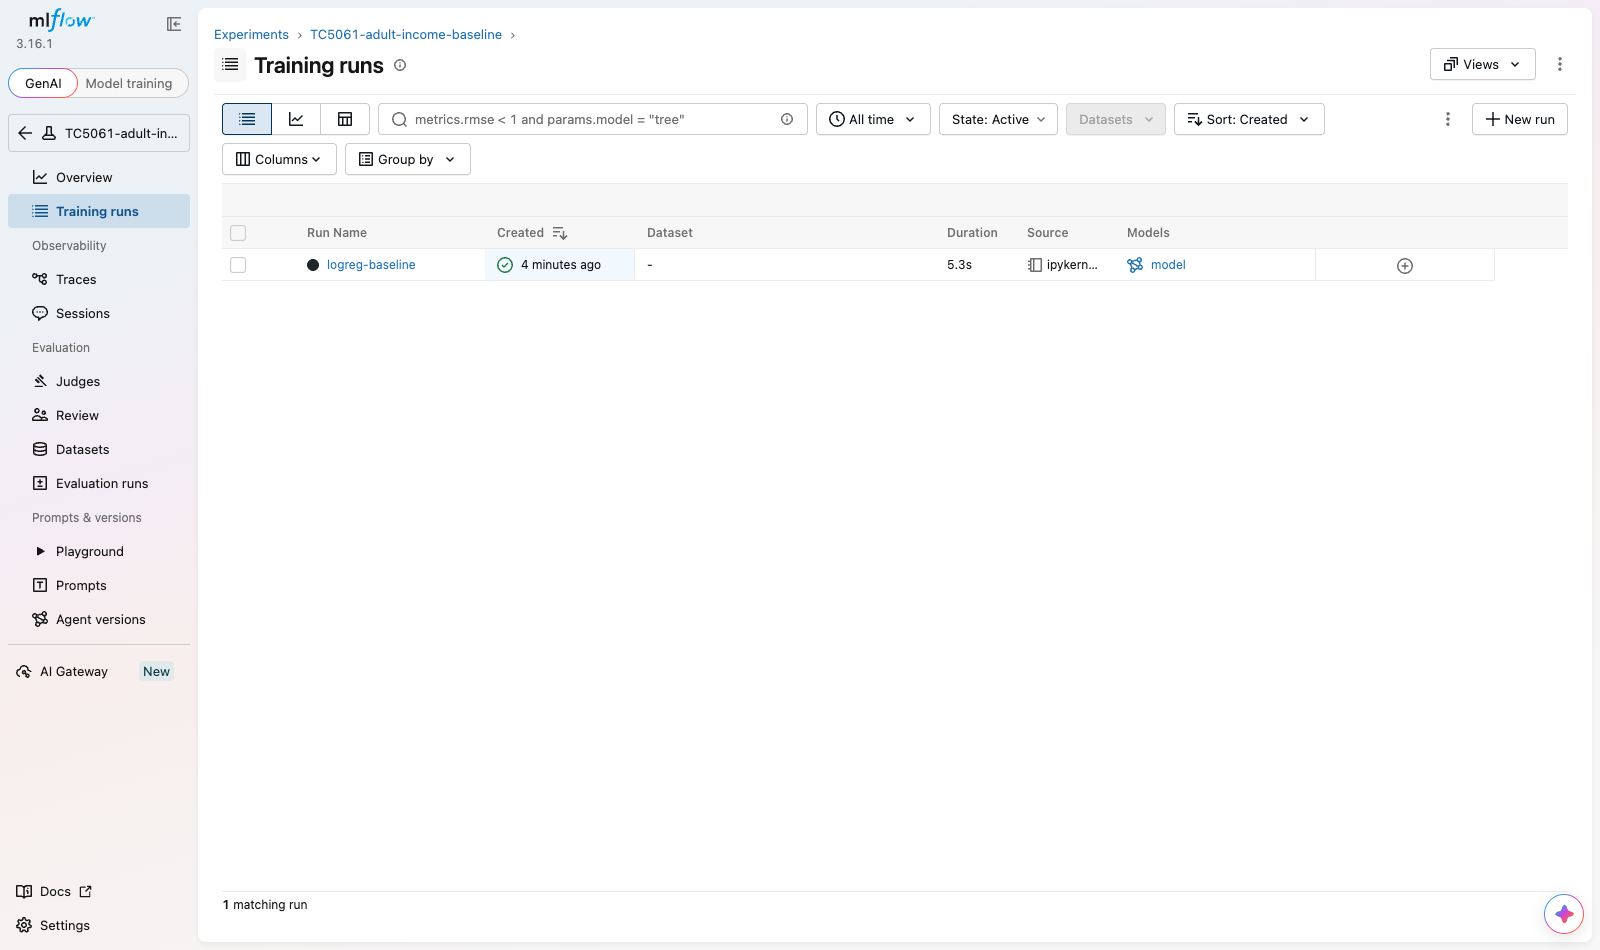

**Figura 2.** Detalle del run: 21 métricas (test, train, Dummy y validación cruzada), tags, Run ID y estado *Finished*.

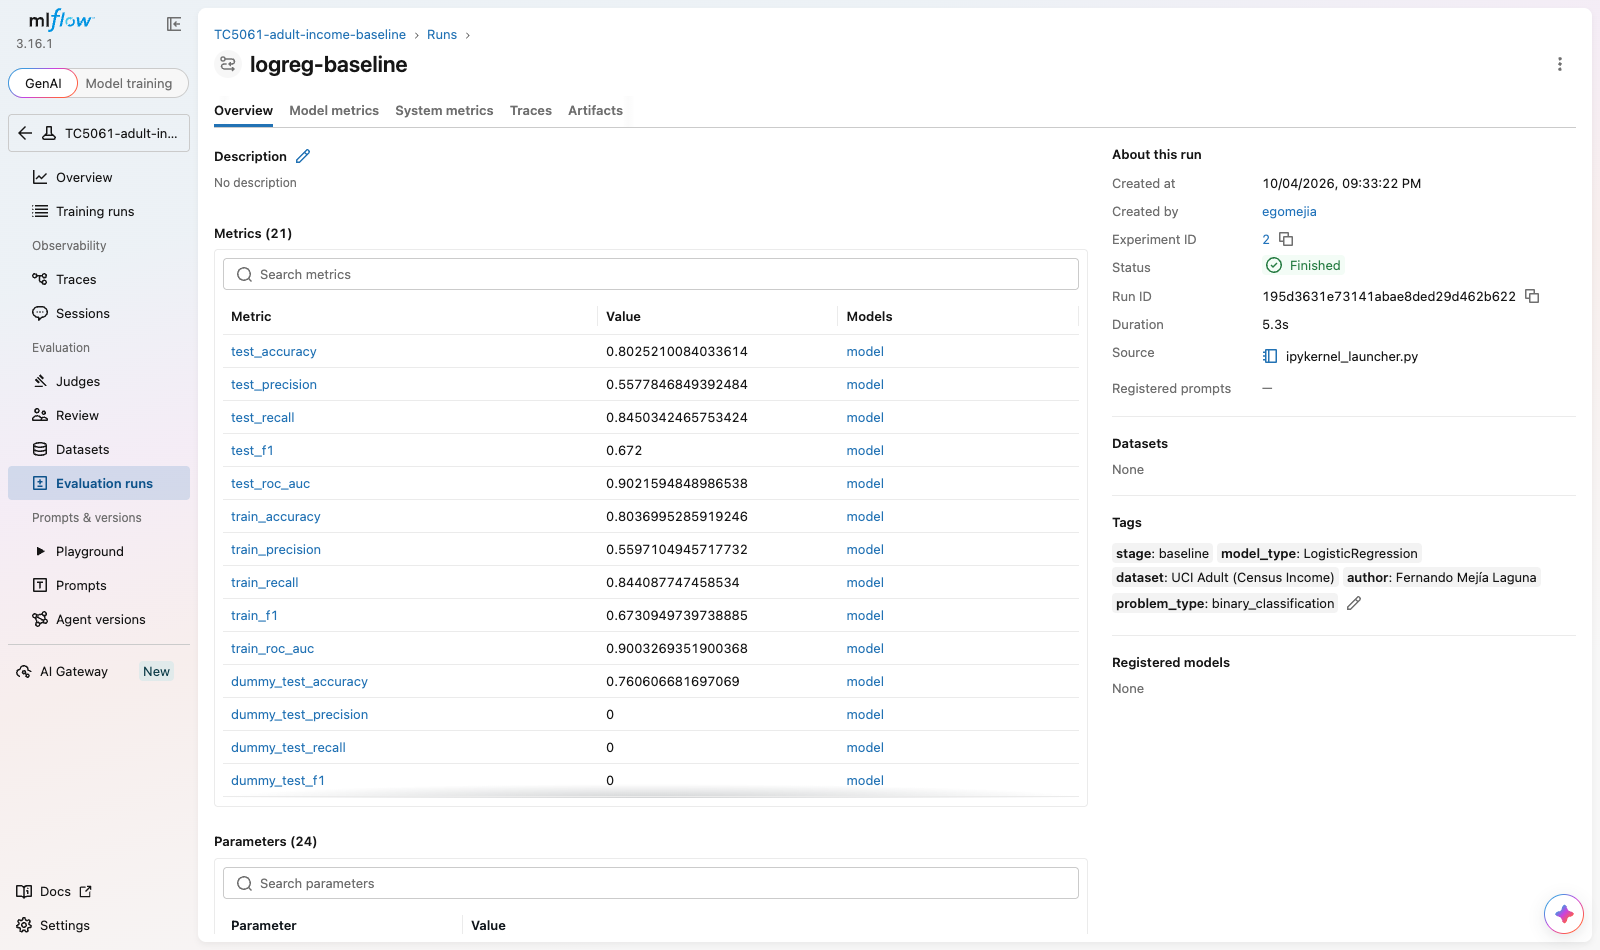

**Figura 3.** Parámetros registrados (24): hiperparámetros del modelo, partición y preprocesamiento, y el modelo registrado (*Logged models*).

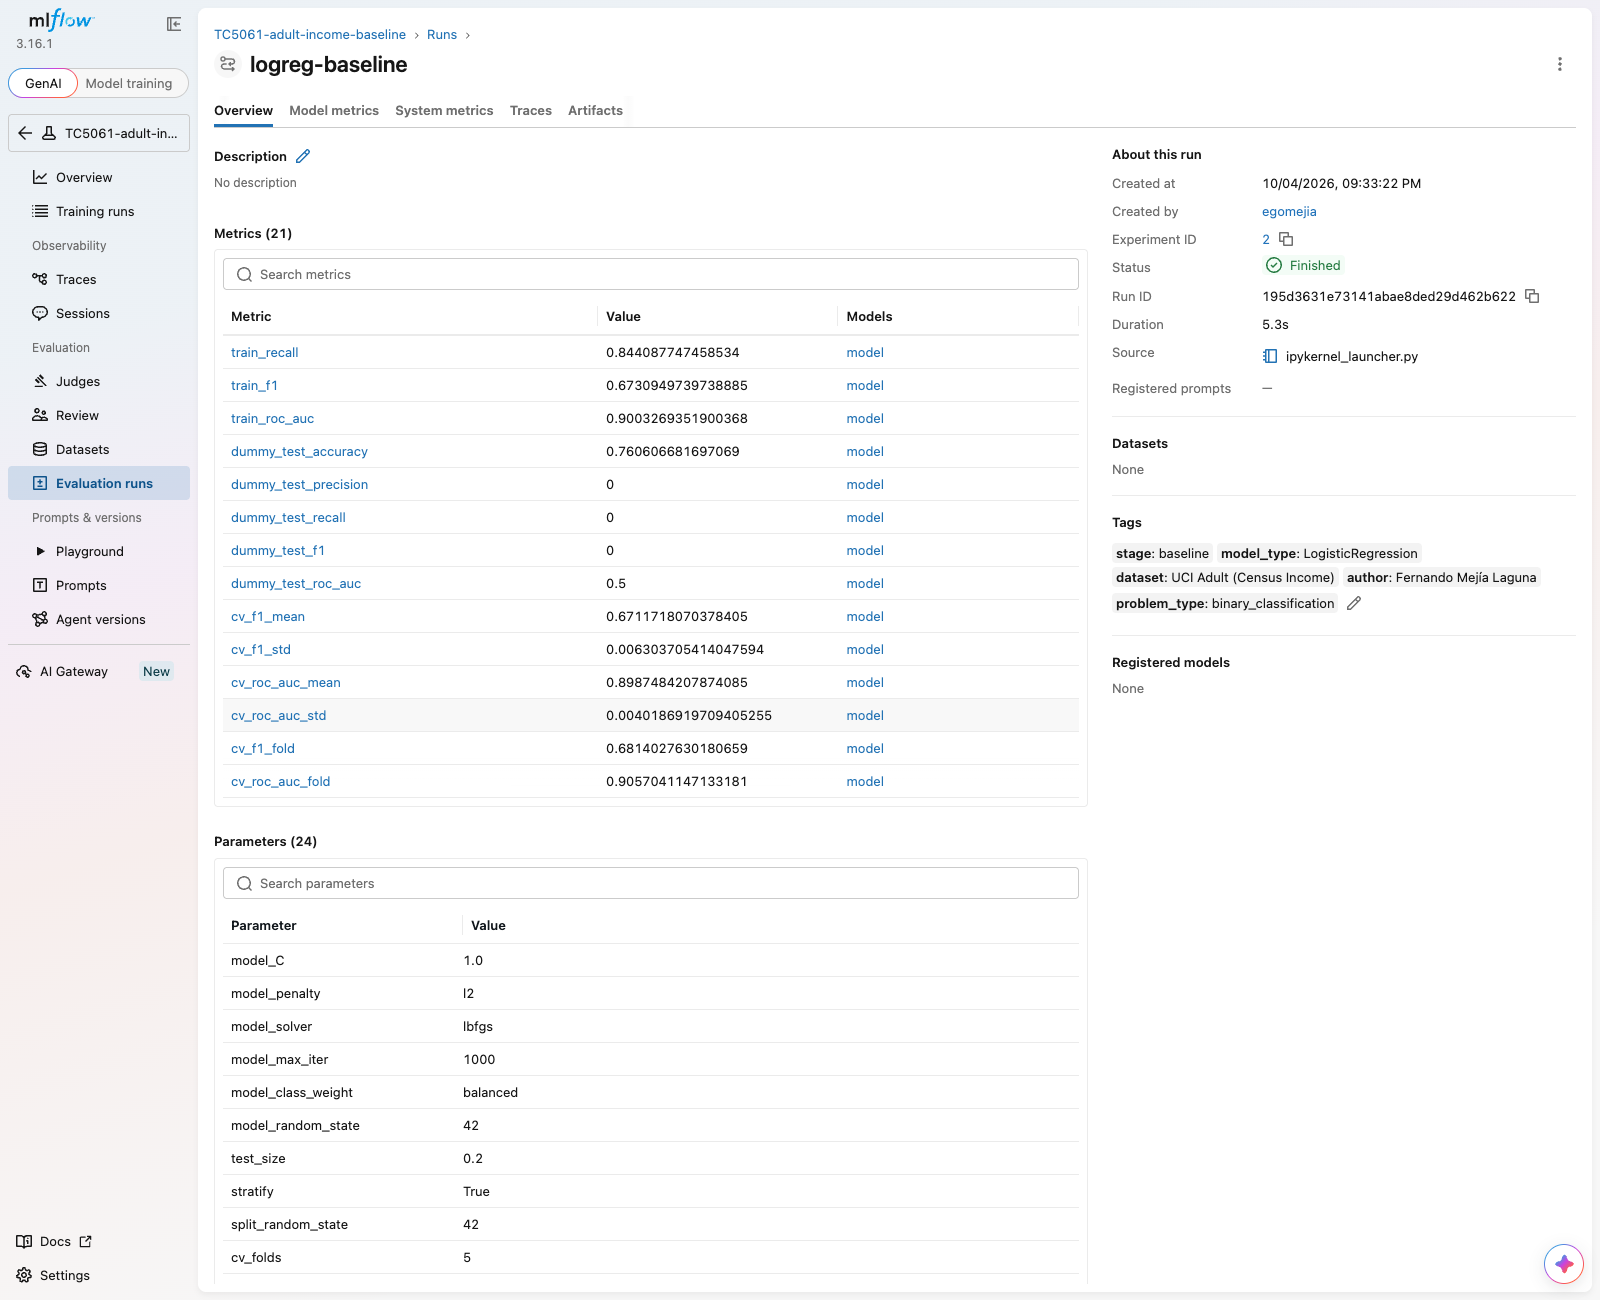

**Figura 4.** Artefactos: figuras del EDA y de evaluación, bitácora de limpieza (`cleaning_log.csv`) y reporte de clasificación.

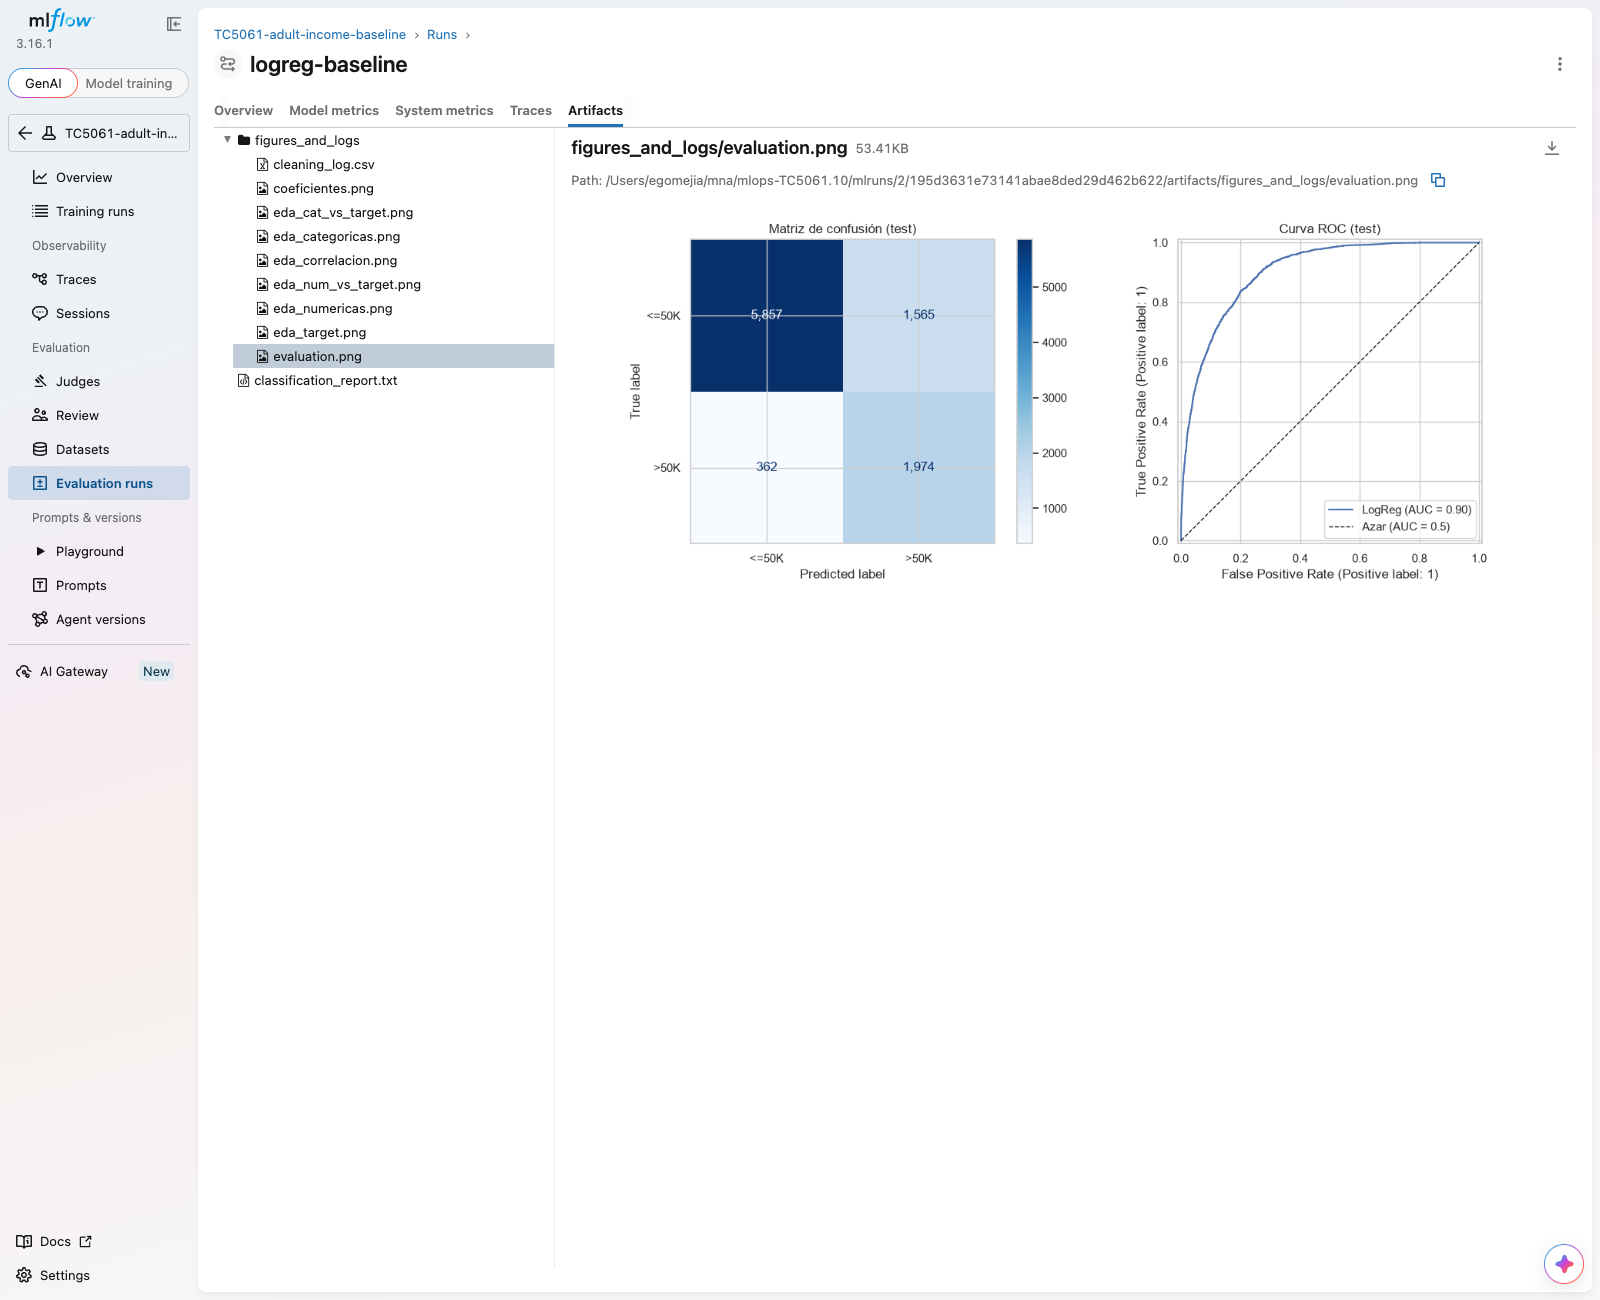

## Paso 7. Reflexión sobre MLOps

Haciendo este notebook me di cuenta de que entrenar el modelo fue la parte más rápida. Lo que más tiempo me llevó fue entender los datos y limpiarlos, y casi todo eso lo hice a mano. Por ejemplo, encontré los faltantes escritos como "?" y las etiquetas con punto en el archivo de prueba porque me puse a revisar columna por columna. Si mañana llegara una versión nueva del dataset, tendría que volver a revisar todo igual, y es fácil que algo se me pase.

Lo primero que cambiaría sería sacar la limpieza del notebook y pasarla a scripts con pruebas que validen los datos antes de entrenar (por ejemplo con Pandera o Great Expectations). Así, si cambia el formato, el proceso falla y no termina entrenando con datos malos sin que nadie se entere. También versionaría los datos junto con el código, con Git y DVC, porque ahora mismo, si UCI modifica el archivo, no tendría manera de reproducir exactamente este resultado.

MLflow me sirvió mucho para guardar parámetros y métricas, pero en este caso solo hay un run. La idea sería usarlo para comparar este baseline contra otros modelos y mandar el mejor al Model Registry, en lugar de decidir viendo números sueltos en el notebook. Y si el modelo llegara a producción, habría que monitorearlo: los datos son de 1994 y además el modelo le da un peso negativo a ser mujer, así que habría que revisar tanto el drift como el sesgo por grupo.

En mi trabajo pasa algo parecido. Muchos análisis empiezan en un notebook, funcionan, y meses después nadie sabe con qué datos o con qué versión del código salieron. Lo que me llevo de esta actividad es que vale la pena registrar y documentar desde el principio, aunque sea un modelo sencillo, porque después ahorra mucho tiempo cuando alguien más necesita revisarlo o reutilizarlo.

## Referencias
- Becker, B. & Kohavi, R. (1996). *Adult* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5XW20
- Géron, A. (2019). *Hands-on Machine Learning with Scikit-Learn, Keras and TensorFlow* (2.ª ed.). O'Reilly Media.
- Lauchande, N. (2021). *Machine Learning Engineering with MLflow*. Packt Publishing.
- MLflow. (s.f.). *MLflow Tracking* [Documentación]. https://mlflow.org/docs/latest/tracking.html
- Treveil, M. et al. (2020). *Introducing MLOps: How to scale machine learning in the enterprise*. O'Reilly Media.